# Communication links with a finite aperture

Predict first: does doubling the integration mesh improve received power? Does a sharper beam always improve net data rate? This notebook separates geometry, channel amplitude, noise and training. It executes the declared scalar model in the [chapter](../chapters/08-communications.md); it does not solve a patterned RIS.

Run all cells in order. Python 3.12 with NumPy and Matplotlib is sufficient for this notebook; the separate audit also uses SciPy. Preserve the reference data before changing parameters: the last cell writes data/chapter-08/reference.json. Scientific plot labels are shared by both editions.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
import sys, hashlib, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT/'simulations').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from simulations.communication_link import (Link, C0, aperture, paths, phase_command,
    channel, noise_power, metrics, error_expectation, training)
p = Link()  # All physical, noise and sampling parameters are editable here.
commands = {'focus': phase_command(p), 'plane': phase_command(p, mode='plane'),
            '2bit': phase_command(p, bits=2)}
xyz, distance, weights = paths(p)
h0 = channel(commands['focus'], p)
gain0 = abs(h0)**2
db = lambda value: 10*np.log10(np.maximum(value, 1e-30))
plt.rcParams.update({'figure.dpi':120, 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.2})
colors = ['#087f8c','#e18431','#7252a1']
evidence = {'metadata': {'parameters':asdict(p), 'model':'declared scalar projected-aperture channel',
    'source_sha256':hashlib.sha256((ROOT/'simulations/communication_link.py').read_text(encoding='utf-8').encode()).hexdigest()}}
print(asdict(p))
print('Channel gain (dB):', db(gain0), 'Noise (dBm):', db(noise_power(p)*1000))
print('SNR (dB):', db(metrics(h0,p)['snr']), 'Gross rate (Mbps):', metrics(h0,p)['net_Mbps'])

{'frequency_GHz': 28.0, 'side_m': 0.48, 'samples_side': 96, 'tx_m': (-10.0, 0.0, 20.0), 'rx_m': (8.0, 0.0, 12.0), 'efficiency': 0.8, 'tx_gain': 1.0, 'rx_gain': 1.0, 'power_dBm': 10.0, 'bandwidth_MHz': 100.0, 'noise_figure_dB': 7.0, 'temperature_K': 290.0}
Channel gain (dB): -87.15820436461476 Noise (dBm): -86.9751871942281
SNR (dB): 9.816982829613352 Gross rate (Mbps): 340.4268724525804


## 1. See the programmed aperture and receiver plane

The left panel is the commanded phase on the **0.48 m square aperture**, at z = 0. It is not a fabricated cell drawing. The right panel keeps each command fixed while moving the receiver along x at z = 12 m. Only the spherical design focuses on the declared target exactly. The plane law discards curvature; the two-bit law rounds the spherical phase to four states. Compare all curves on the same ideal-target reference.

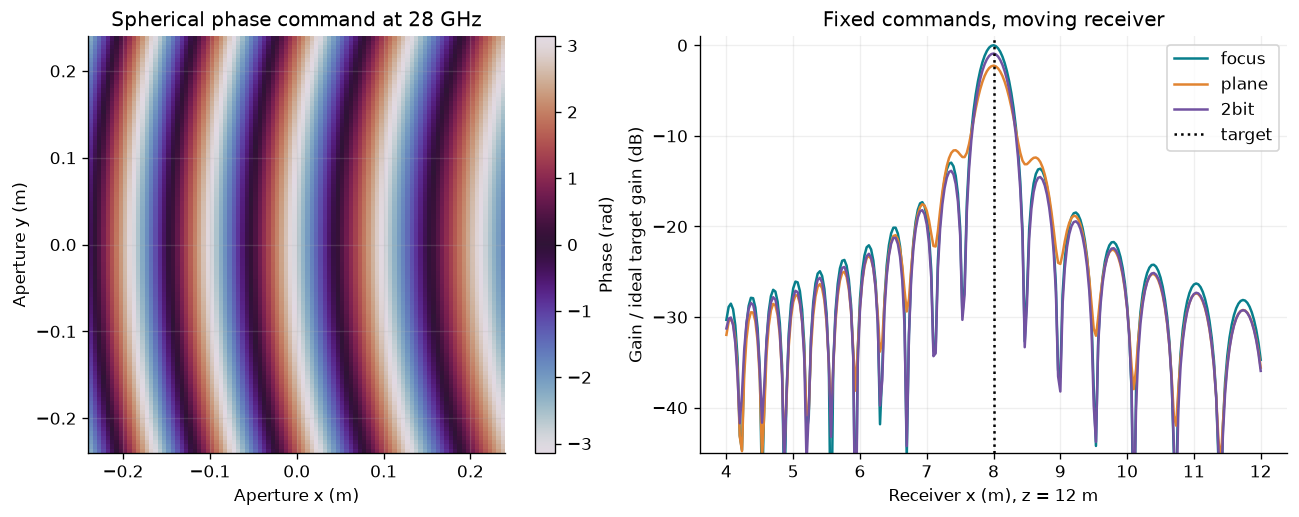

In [2]:
xs = np.linspace(4,12,241)
profiles = {key:np.array([abs(channel(g,p,(x,0,p.rx_m[2])))**2 for x in xs]) for key,g in commands.items()}
fig,ax=plt.subplots(1,2,figsize=(11.5,4.2),layout='constrained')
im=ax[0].imshow(np.angle(commands['focus']).reshape(p.samples_side,-1),origin='lower',
    extent=[-p.side_m/2,p.side_m/2,-p.side_m/2,p.side_m/2],cmap='twilight',vmin=-np.pi,vmax=np.pi)
ax[0].set(xlabel='Aperture x (m)',ylabel='Aperture y (m)',title='Spherical phase command at 28 GHz')
fig.colorbar(im,ax=ax[0],label='Phase (rad)')
for (key,curve),color in zip(profiles.items(),colors):
    ax[1].plot(xs,db(curve/gain0),label=key,color=color)
ax[1].axvline(p.rx_m[0],ls=':',color='black',label='target')
ax[1].set(xlabel='Receiver x (m), z = 12 m',ylabel='Gain / ideal target gain (dB)',
          ylim=(-45,1),title='Fixed commands, moving receiver')
ax[1].legend()
plt.show()
evidence['focus']={'x_m':xs.tolist(),'gain':{k:v.tolist() for k,v in profiles.items()},
    'phase':{k:np.angle(v).reshape(p.samples_side,-1)[::4,::4].tolist() for k,v in commands.items()},
    'target_gain':{k:float(abs(channel(v,p))**2) for k,v in commands.items()}}

## 2. Area, sampling and coherent interference

At fixed area, a finer midpoint mesh converges to an integral. The second panel changes physical area while retargeting each aperture; the dashed far-field expression is a comparison, not an exact near-field theorem. The last panel adds a direct Friis path with an assigned 10-dB excess **power** loss, then sweeps the common surface phase relative to that direct path. The endpoints remain at their reference positions and the RIS path stays focused. Adding fields can reduce received power.

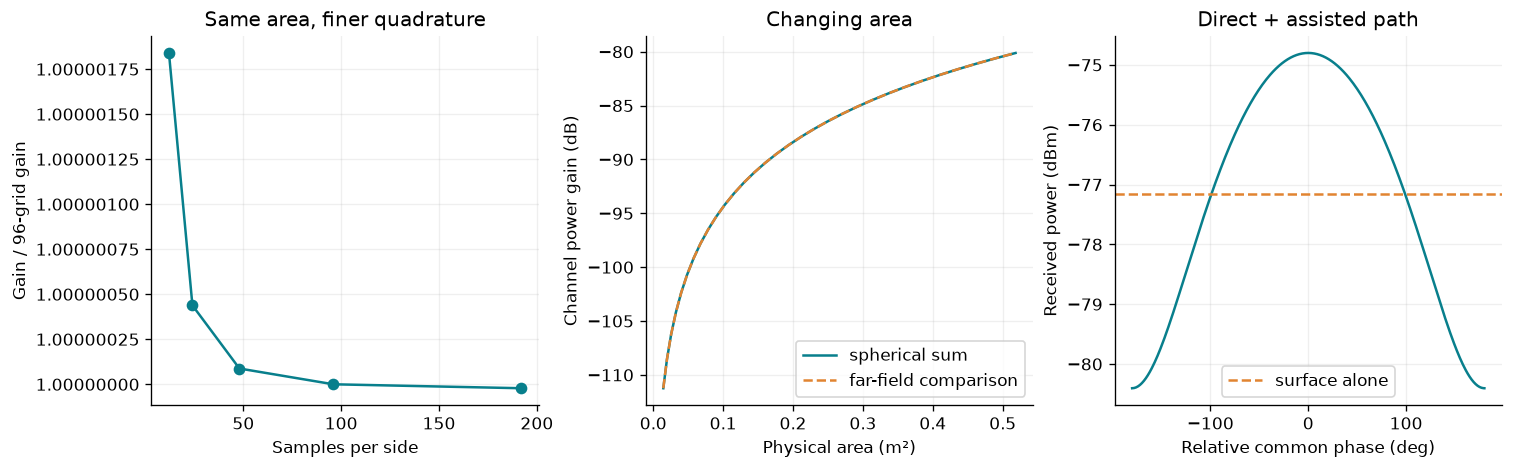

In [3]:
ns = [12,24,48,96,192]
grid_gain=[]
for n in ns:
    q=replace(p,samples_side=n); grid_gain.append(abs(channel(phase_command(q),q))**2)
sides=np.linspace(.12,.72,31); area_gain=[]
for side in sides:
    q=replace(p,side_m=float(side)); area_gain.append(abs(channel(phase_command(q),q))**2)
t=np.array(p.tx_m);r=np.array(p.rx_m)
rt=np.linalg.norm(t);rr=np.linalg.norm(r)
far_gain=p.efficiency*(t[2]/rt)*(r[2]/rr)*sides**4/(16*np.pi**2*rt**2*rr**2)
direct_distance=np.linalg.norm(t-r)
direct_amp=C0/(p.frequency_GHz*1e9)/(4*np.pi*direct_distance)*10**(-10/20)
phase=np.linspace(-180,180,361)
combined=abs(direct_amp+abs(h0)*np.exp(1j*np.deg2rad(phase)))**2
fig,ax=plt.subplots(1,3,figsize=(12.5,3.8),layout='constrained')
ax[0].plot(ns,np.array(grid_gain)/gain0,'o-',color=colors[0])
ax[0].set(xlabel='Samples per side',ylabel='Gain / 96-grid gain',title='Same area, finer quadrature')
ax[0].ticklabel_format(axis='y',style='plain',useOffset=False)
ax[1].plot(sides**2,db(area_gain),label='spherical sum',color=colors[0])
ax[1].plot(sides**2,db(far_gain),'--',label='far-field comparison',color=colors[1])
ax[1].set(xlabel='Physical area (m²)',ylabel='Channel power gain (dB)',title='Changing area');ax[1].legend()
ax[2].plot(phase,p.power_dBm+db(combined),color=colors[0])
ax[2].axhline(p.power_dBm+db(gain0),ls='--',color=colors[1],label='surface alone')
ax[2].set(xlabel='Relative common phase (deg)',ylabel='Received power (dBm)',title='Direct + assisted path');ax[2].legend()
plt.show()
evidence['power']={'samples':ns,'grid_gain':grid_gain,'side_m':sides.tolist(),'area_gain':area_gain,
    'far_gain':far_gain.tolist(),'phase_deg':phase.tolist(),'combined_gain':combined.tolist(),
    'direct_amplitude':float(direct_amp),'direct_excess_loss_dB':10.}

## 3. A phase setting is not a true time delay

Freeze the 28-GHz command and sweep frequency with identical source power. The ideal delay benchmark cancels path differences at each frequency; it assumes nondispersive amplitude and realizable relative delays and is not the response of a simulated device. The lateral peak moves with frequency. The frequency panel plots channel gain, not broadband throughput; computing wideband rate also requires a power spectral density and noise integration.

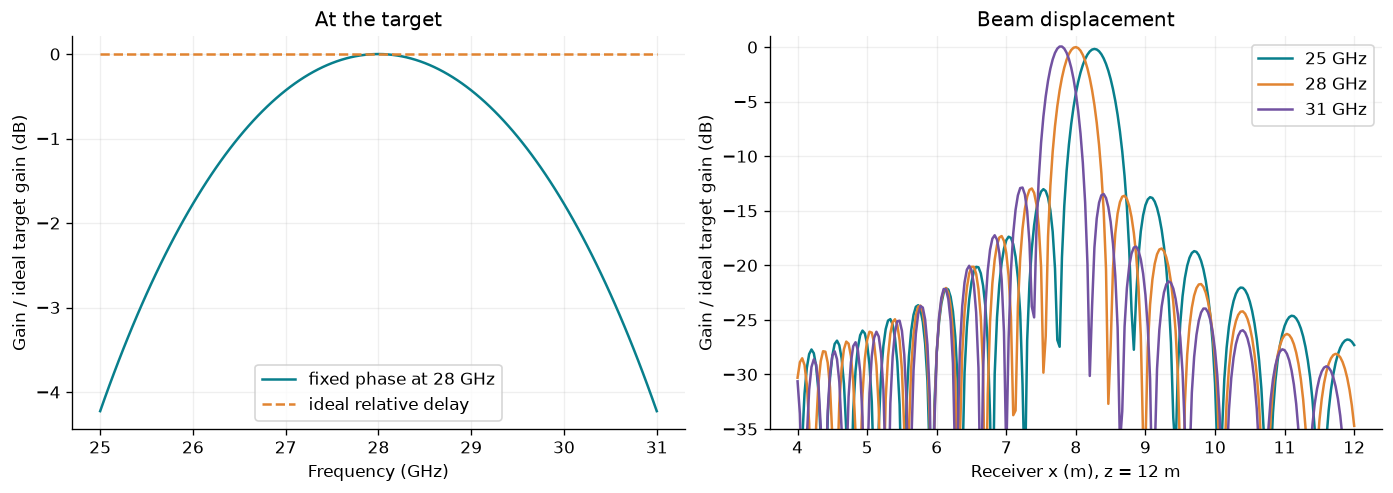

In [4]:
frequencies=np.linspace(25,31,121)
fixed=np.array([abs(channel(commands['focus'],p,frequency_GHz=f))**2 for f in frequencies])
ideal=np.array([paths(p,frequency_GHz=f)[2].sum()**2 for f in frequencies])
wide_profiles={str(f):np.array([abs(channel(commands['focus'],p,(x,0,p.rx_m[2]),f))**2 for x in xs]) for f in (25,28,31)}
fig,ax=plt.subplots(1,2,figsize=(11.5,4),layout='constrained')
ax[0].plot(frequencies,db(fixed/gain0),color=colors[0],label='fixed phase at 28 GHz')
ax[0].plot(frequencies,db(ideal/gain0),'--',color=colors[1],label='ideal relative delay')
ax[0].set(xlabel='Frequency (GHz)',ylabel='Gain / ideal target gain (dB)',title='At the target');ax[0].legend()
for (key,curve),color in zip(wide_profiles.items(),colors):
    ax[1].plot(xs,db(curve/gain0),label=key+' GHz',color=color)
ax[1].set(xlabel='Receiver x (m), z = 12 m',ylabel='Gain / ideal target gain (dB)',
          ylim=(-35,1),title='Beam displacement');ax[1].legend()
plt.show()
evidence['bandwidth']={'GHz':frequencies.tolist(),'fixed_gain':fixed.tolist(),'delay_gain':ideal.tolist(),
    'profiles':{k:v.tolist() for k,v in wide_profiles.items()}}

## 4. Error statistics and training cost

The left panel compares the exact mean-power formula with 256 seeded realizations of independent Gaussian phase errors. Error bars show ±2 standard errors of the sample mean, not outage quantiles. The right panel searches noiseless pilot powers for a user at x = 8.37 m, z = 12 m using K focus points covering x = 4–12 m; K = 1 uses x = 8 m. One pilot symbol is charged per candidate in a 200-symbol block. Geometry and gains are otherwise fixed. This is exhaustive beam selection, not a channel estimator.

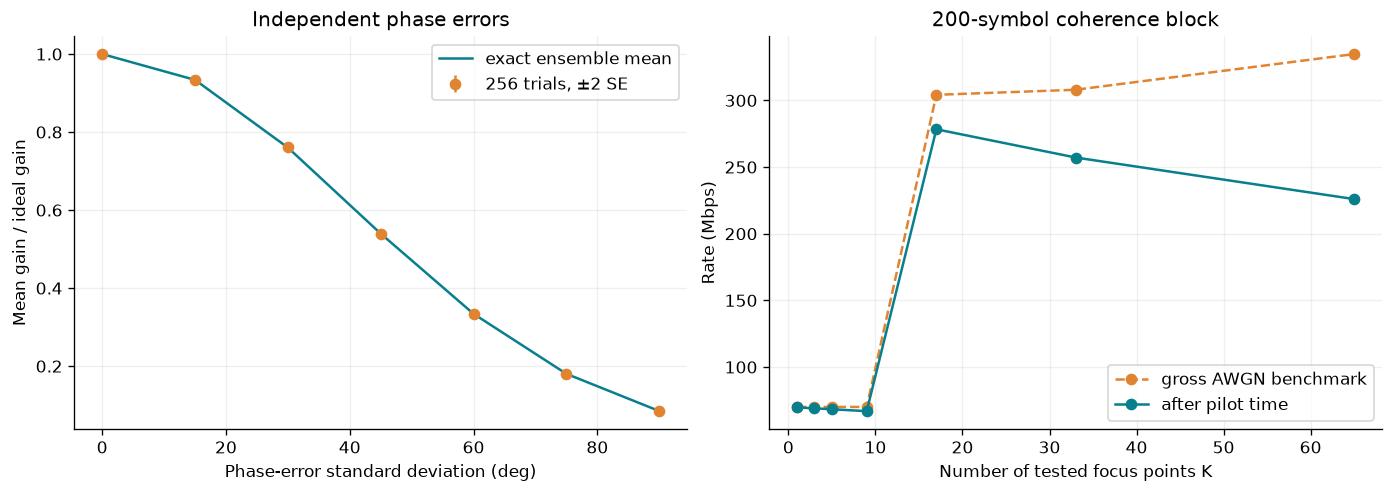

Best tested net-rate codebook: {'count': 17, 'selected_x': 8.5, 'gain': 1.4520166086832795e-09, 'gross_Mbps': 304.191973778099, 'net_Mbps': 278.3356560069606}


In [5]:
sigma=np.linspace(0,90,7);rng=np.random.default_rng(8);means=[];sem=[]
for s in sigma:
    trials=abs(np.exp(1j*rng.normal(0,np.deg2rad(s),(256,len(weights))))@weights)**2/gain0
    means.append(float(trials.mean()));sem.append(float(trials.std(ddof=1)/np.sqrt(len(trials))))
expected=error_expectation(weights,np.deg2rad(sigma))/gain0
train=training(p);counts=np.array([v['count'] for v in train])
fig,ax=plt.subplots(1,2,figsize=(11.5,4),layout='constrained')
ax[0].plot(sigma,expected,label='exact ensemble mean',color=colors[0])
ax[0].errorbar(sigma,means,yerr=2*np.array(sem),fmt='o',label='256 trials, ±2 SE',color=colors[1])
ax[0].set(xlabel='Phase-error standard deviation (deg)',ylabel='Mean gain / ideal gain',title='Independent phase errors');ax[0].legend()
ax[1].plot(counts,[v['gross_Mbps'] for v in train],'o--',label='gross AWGN benchmark',color=colors[1])
ax[1].plot(counts,[v['net_Mbps'] for v in train],'o-',label='after pilot time',color=colors[0])
ax[1].set(xlabel='Number of tested focus points K',ylabel='Rate (Mbps)',title='200-symbol coherence block');ax[1].legend()
plt.show()
evidence['training']={'rows':train,'coherence':200,'user_x_m':8.37,'sigma_deg':sigma.tolist(),
    'mean_ratio':expected.tolist(),'mc_ratio':means,'mc_SE':sem,'trials':256,'seed':8}
print('Best tested net-rate codebook:',max(train,key=lambda row:row['net_Mbps']))

## 5. Save, audit and challenge the model

The browser uses these saved arrays and only recomputes simple displayed noise/rate expressions. Run python scripts/validate_chapter08.py separately: it checks adaptive continuous quadrature, an independent scalar-loop implementation, far-field normalization, reciprocity, coherent bounds, sinc and Gaussian identities, rate accounting and invalid inputs.

Try one defensible extension: a displaced receiver, a measured complex state library, noisy beam selection or multiple users. Keep baseline data and distinguish model error from integration error. A numerical check of this model is not validation of a fabricated surface or measured wireless link.

In [6]:
out=ROOT/'data/chapter-08';out.mkdir(parents=True,exist_ok=True)
(out/'reference.json').write_text(json.dumps(evidence,separators=(',',':'))+'\n',encoding='utf-8')
print('Saved reference.json; no full-wave simulation or measurement is represented.')

Saved reference.json; no full-wave simulation or measurement is represented.
